# Predicción de suscripción a depósitos a plazo — Bank Marketing

**Machine Learning Zoomcamp 2026 · Capstone 1**

Este notebook construye un modelo de clasificación binaria que estima si un cliente de un banco contratará un **depósito a plazo** después de una campaña de marketing telefónico. Se usa el dataset público *Bank Marketing* del repositorio UCI.

El objetivo de negocio es **priorizar las llamadas**: llamar a todos los clientes es caro, así que el modelo ordena a los clientes por probabilidad de suscripción para que el equipo comercial llame primero a los más prometedores.

El modelo final se reproduce con `train.py` y se sirve con `app.py` (Flask) dentro de un contenedor Docker.

## 1. Descripción del problema

Un banco portugués realizó campañas de marketing telefónico para ofrecer un **depósito a plazo** (*term deposit*). El dataset registra, para cada cliente contactado, sus datos personales y financieros, los detalles de la campaña y si finalmente aceptó el producto.

- **Variable objetivo:** `y` — `yes` si el cliente contrató el depósito, `no` si no lo hizo.
- **Problema:** clasificación binaria con **desbalance** (solo ~11.7% de los clientes dicen `yes`).
- **Métrica principal:** **ROC AUC**, porque mide la capacidad del modelo de ordenar clientes por riesgo/probabilidad independientemente del umbral. Como métrica secundaria se reporta **PR AUC** (más informativa con clases desbalanceadas), además de precisión, recall y F1.
- **Uso práctico:** el equipo comercial introduce los datos que conoce *antes* de llamar y obtiene una probabilidad. Los clientes con mayor probabilidad se llaman primero.

> **Decisión clave:** se excluye la variable `duration` (duración de la llamada). Solo se conoce después de hablar con el cliente, por lo que incluirla produciría una fuga de información (*data leakage*) y un modelo inútil en producción.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 12

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

In [2]:
DATA_PATH = Path("data/bank-full.csv")
df = pd.read_csv(DATA_PATH, sep=";")
print(f"Filas: {len(df):,}  |  Columnas: {df.shape[1]}")
df.head()

Filas: 45,211  |  Columnas: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 2. Análisis exploratorio de datos (EDA)

Antes de modelar conviene entender la distribución del objetivo, el tipo de cada variable y la relación entre las características y la suscripción.

In [3]:
print("Valores faltantes:", int(df.isna().sum().sum()))
print("\nConteo de tipos de datos:")
print(df.dtypes.value_counts())
df.describe().T.round(2)

Valores faltantes: 0

Conteo de tipos de datos:
str      10
int64     7
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


### 2.1 Distribución del objetivo

y
no     39922
yes     5289
Name: count, dtype: int64

Proporción:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


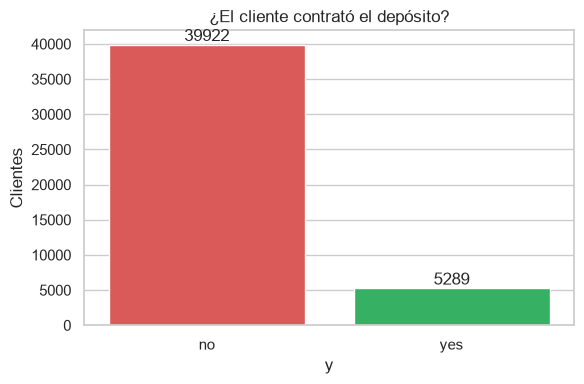

In [4]:
conteo = df["y"].value_counts()
print(conteo)
print("\nProporción:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="y", hue="y", palette=["#ef4444", "#22c55e"], legend=False, ax=ax)
ax.set_title("¿El cliente contrató el depósito?")
ax.set_xlabel("y")
ax.set_ylabel("Clientes")
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%d")
plt.tight_layout()
plt.show()

El objetivo está **fuertemente desbalanceado**: aproximadamente 1 de cada 9 clientes dice `yes`. Por eso la exactitud (*accuracy*) es engañosa —un modelo que siempre prediga `no` acertaría ~88%— y se prioriza ROC AUC junto con precisión y recall de la clase positiva.

### 2.2 Variables numéricas

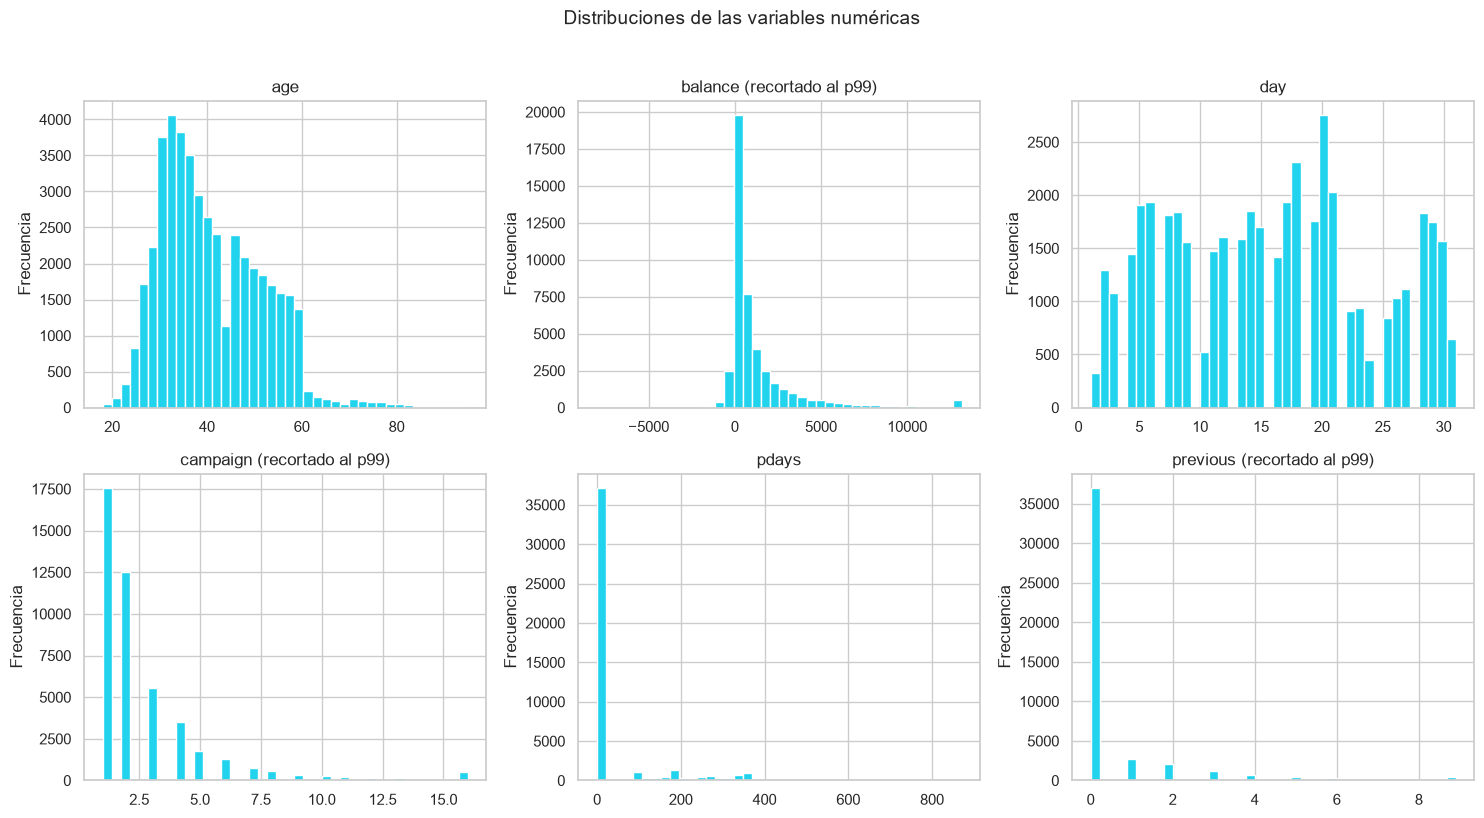

In [5]:
columnas_numericas = ["age", "balance", "day", "campaign", "pdays", "previous"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), columnas_numericas):
    datos = df[col]
    recortado = col in ("balance", "campaign", "previous")
    if recortado:
        datos = datos.clip(upper=datos.quantile(0.99))
    ax.hist(datos, bins=40, color="#22d3ee", edgecolor="white")
    ax.set_title(col + (" (recortado al p99)" if recortado else ""))
    ax.set_ylabel("Frecuencia")
plt.suptitle("Distribuciones de las variables numéricas", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

### 2.3 Variables categóricas

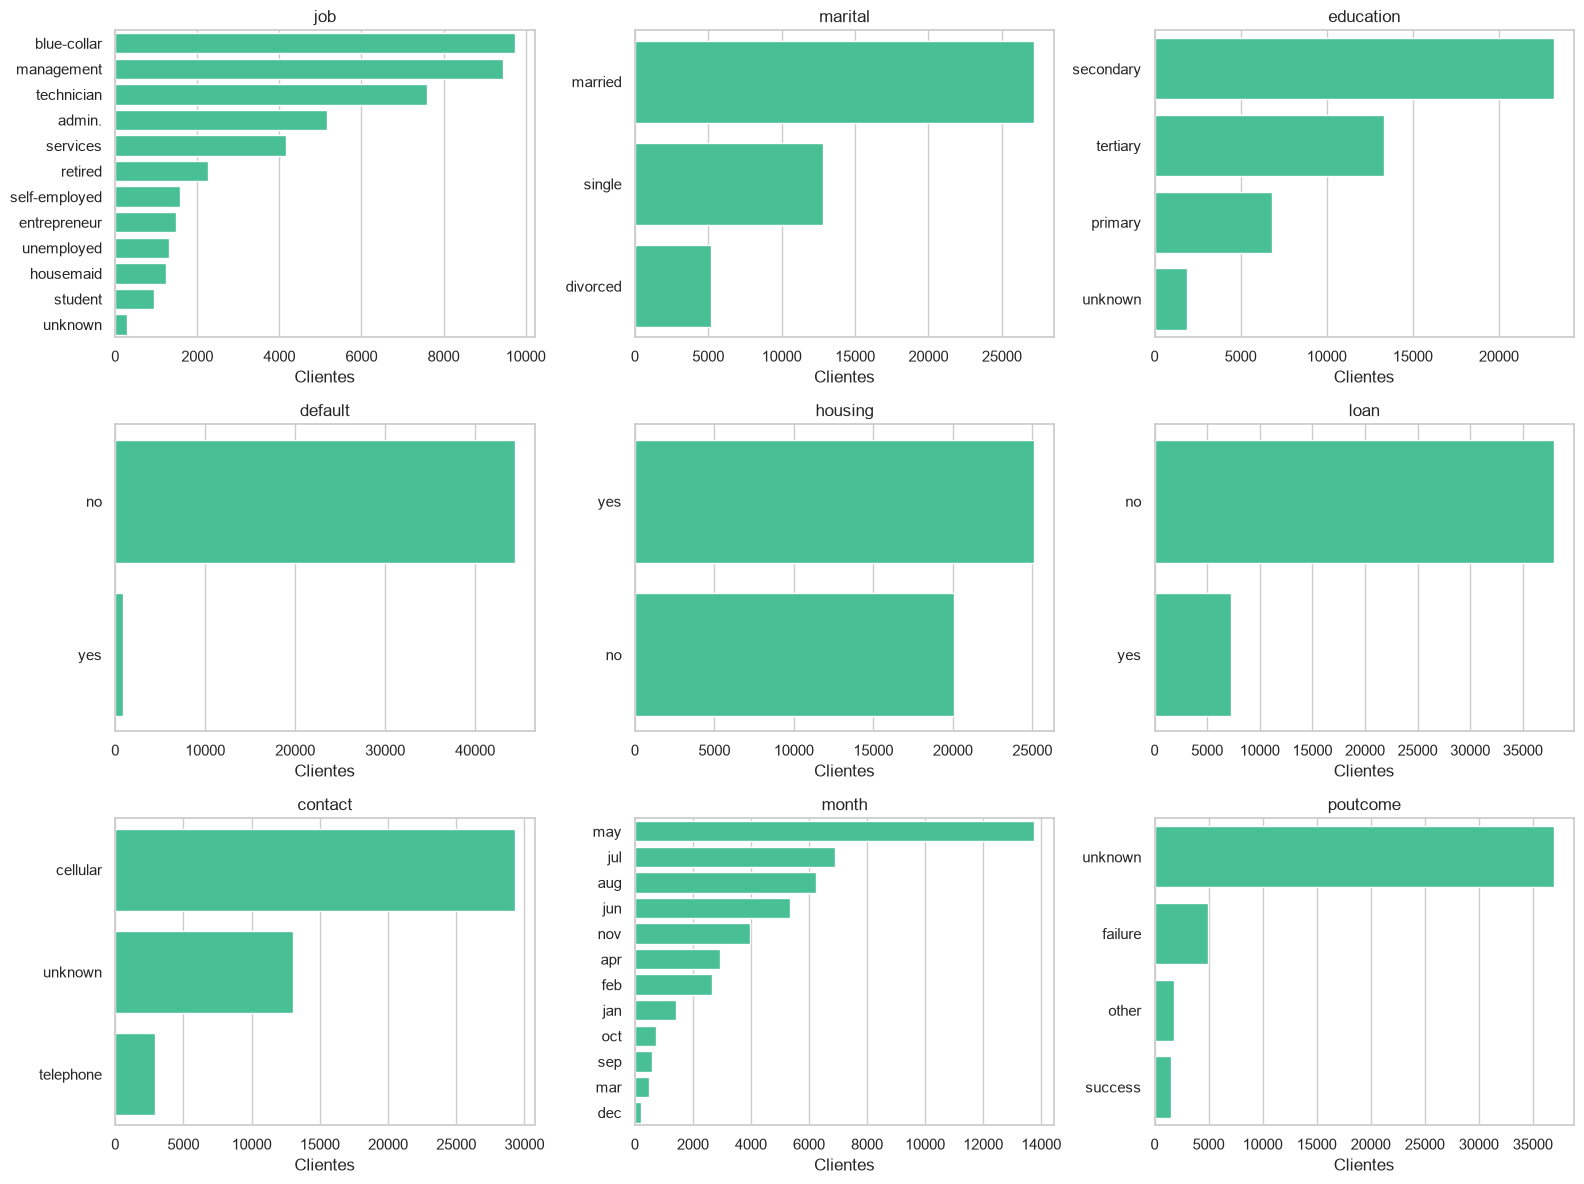

In [6]:
columnas_categoricas = [
    "job", "marital", "education", "default", "housing", "loan", "contact",
    "month", "poutcome",
]
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.ravel(), columnas_categoricas):
    orden = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=orden, color="#34d399", ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
    ax.set_xlabel("Clientes")
plt.tight_layout()
plt.show()

### 2.4 Tasa de suscripción por categoría

En lugar de mirar solo los conteos, interesa ver **qué grupos convierten mejor**. Esto guía la interpretación del modelo y confirma que las variables categóricas aportan señal.

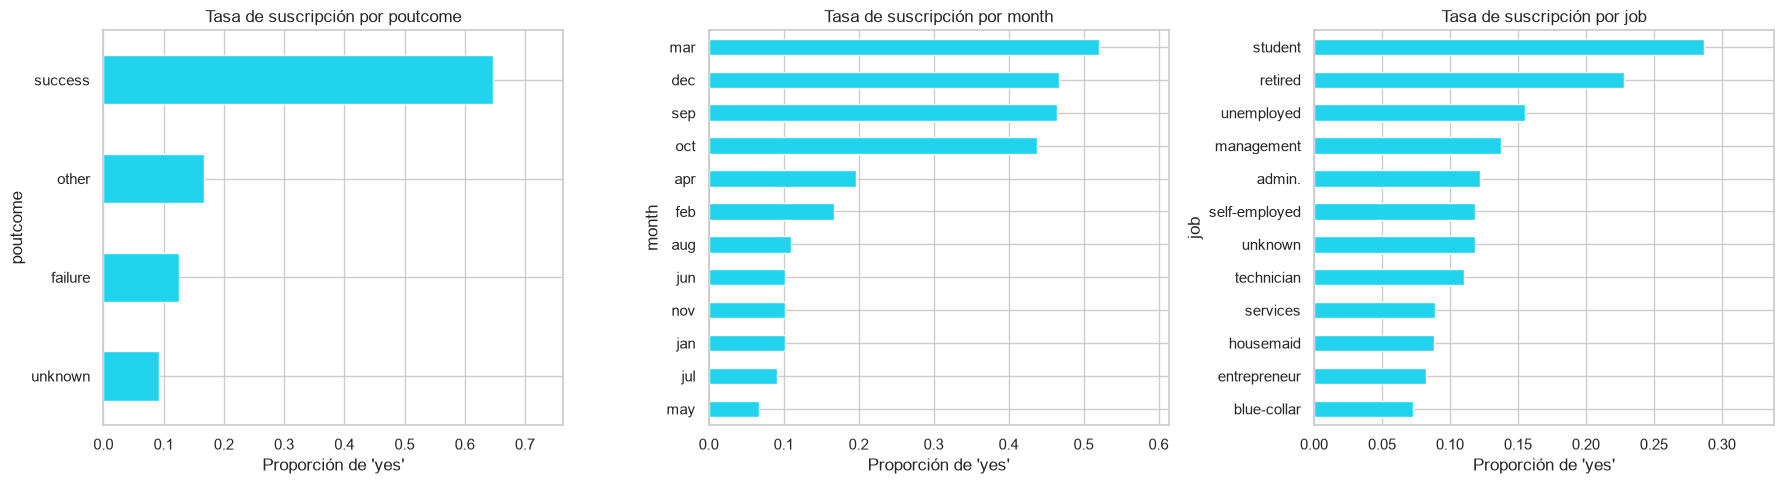

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["poutcome", "month", "job"]):
    tasa = (
        df.groupby(col)["y"]
        .apply(lambda s: (s == "yes").mean())
        .sort_values(ascending=False)
    )
    tasa.plot(kind="barh", ax=ax, color="#22d3ee")
    ax.set_title(f"Tasa de suscripción por {col}")
    ax.set_xlabel("Proporción de 'yes'")
    ax.set_xlim(0, tasa.max() * 1.18)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

Los clientes con un **resultado exitoso en la campaña anterior** (`poutcome = success`) convierten muchísimo más que el resto, y ciertos meses (marzo, septiembre, octubre, diciembre) tienen tasas altas porque concentran campañas concretas. Esto son señales reales que el modelo puede explotar.

### 2.5 La trampa de `duration` (fuga de información)

`duration` es la duración en segundos de la última llamada. El propio dataset advierte que **influye muchísimo** en el objetivo… precisamente porque solo se conoce cuando la llamada ya terminó. Veámoslo.

       count   mean    std  min    25%    50%    75%     max
y                                                           
no   39922.0  221.2  207.4  0.0   95.0  164.0  279.0  4918.0
yes   5289.0  537.3  392.5  8.0  244.0  426.0  725.0  3881.0



ROC AUC usando solo `duration`: 0.8076


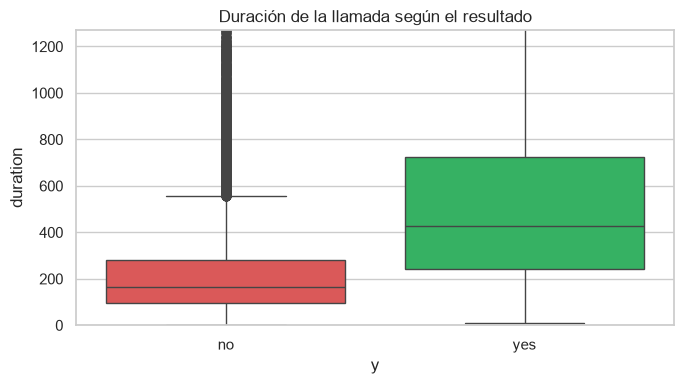

In [8]:
print(df.groupby("y")["duration"].describe().round(1))

auc_solo_duracion = roc_auc_score(
    (df["y"] == "yes").astype(int), df["duration"]
)
print(f"\nROC AUC usando solo `duration`: {auc_solo_duracion:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x="y", y="duration", hue="y", palette=["#ef4444", "#22c55e"], legend=False, ax=ax)
ax.set_ylim(0, df["duration"].quantile(0.99))
ax.set_title("Duración de la llamada según el resultado")
plt.tight_layout()
plt.show()

Una sola variable —que no está disponible antes de llamar— alcanza un ROC AUC alto. Si se incluyera, el modelo parecería excelente en el notebook pero sería **inútil en producción**, porque el banco necesita decidir *a quién* llamar antes de la llamada.

**Conclusión:** `duration` se descarta en todo el modelado.

### 2.6 Correlación entre variables numéricas

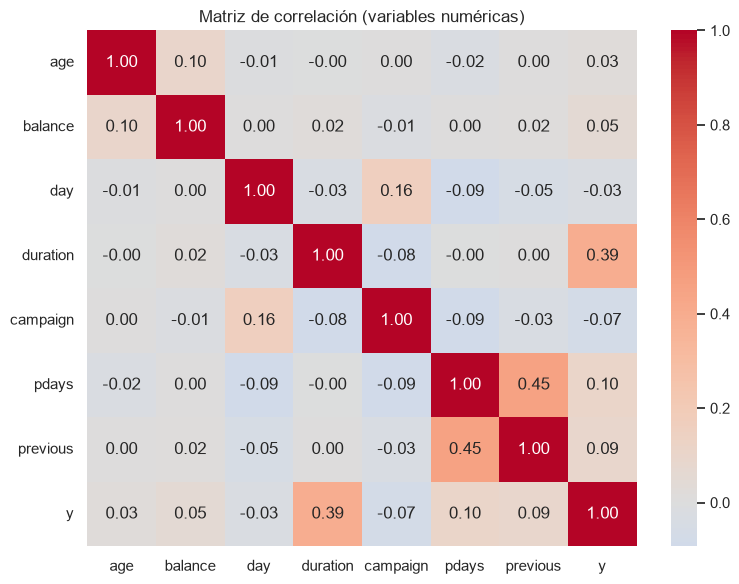

In [9]:
df_corr = df.copy()
df_corr["y"] = df_corr["y"].map({"no": 0, "yes": 1})
matriz = df_corr[
    ["age", "balance", "day", "duration", "campaign", "pdays", "previous", "y"]
].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matriz de correlación (variables numéricas)")
plt.tight_layout()
plt.show()

## 3. Preparación de datos

1. Se convierte `y` a `0/1`.
2. Se elimina `duration`.
3. Las variables numéricas se imputan con la mediana y se escalan con `StandardScaler`.
4. Las variables categóricas se imputan con la moda y se codifican con `OneHotEncoder` (ignorando categorías desconocidas en producción).
5. Todo se encapsula en un `Pipeline` para que el preprocesamiento se ajuste **solo con el conjunto de entrenamiento** y no haya fuga de datos.

In [10]:
TARGET = "y"
df_model = df.copy()
df_model[TARGET] = (df_model[TARGET] == "yes").astype(int)
df_model = df_model.drop(columns=["duration"])

NUMERIC_FEATURES = ["age", "balance", "day", "campaign", "pdays", "previous"]
CATEGORICAL_FEATURES = [
    "job", "marital", "education", "default", "housing", "loan", "contact",
    "month", "poutcome",
]
FEATURES = [
    "age", "job", "marital", "education", "default", "balance", "housing",
    "loan", "contact", "day", "month", "campaign", "pdays", "previous",
    "poutcome",
]

X = df_model[FEATURES]
y = df_model[TARGET]

print("Características:", len(FEATURES))
print("Tasa de positivos:", f"{y.mean():.2%}")

Características: 15
Tasa de positivos: 11.70%


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Entrenamiento: {len(X_train):,}")
print(f"Prueba:        {len(X_test):,}")
print("Tasa de positivos en train:", f"{y_train.mean():.2%}")
print("Tasa de positivos en test :", f"{y_test.mean():.2%}")

Entrenamiento: 36,168
Prueba:        9,043
Tasa de positivos en train: 11.70%
Tasa de positivos en test : 11.70%


In [12]:
def build_preprocessor() -> ColumnTransformer:
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric, NUMERIC_FEATURES),
        ("cat", categorical, CATEGORICAL_FEATURES),
    ])


def build_pipeline(estimator) -> Pipeline:
    return Pipeline([
        ("preprocessor", build_preprocessor()),
        ("classifier", estimator),
    ])


print("Pipeline de preprocesamiento listo")

Pipeline de preprocesamiento listo


## 4. Comparación de modelos

Se comparan tres familias con **validación cruzada estratificada de 5 pliegues** y ROC AUC:

- **Regresión Logística** — modelo lineal de referencia, rápido e interpretable.
- **Random Forest** — ensamble de árboles, captura interacciones no lineales.
- **Gradient Boosting (HistGradientBoosting)** — boosting de árboles, suele ser el más fuerte en datos tabulares.

Todos usan `class_weight="balanced"` para compensar el desbalance.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidatos = {
    "Regresión Logística": build_pipeline(
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "Random Forest": build_pipeline(
        RandomForestClassifier(
            n_estimators=300, min_samples_leaf=5, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=1,
        )
    ),
    "Gradient Boosting": build_pipeline(
        HistGradientBoostingClassifier(
            max_iter=200, learning_rate=0.1, class_weight="balanced",
            random_state=RANDOM_STATE,
        )
    ),
}

resultados_cv = {}
for nombre, pipeline in candidatos.items():
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    resultados_cv[nombre] = scores
    print(f"{nombre:22s}  ROC AUC = {scores.mean():.4f} ± {scores.std():.4f}")

Regresión Logística     ROC AUC = 0.7637 ± 0.0032


Random Forest           ROC AUC = 0.7942 ± 0.0044


Gradient Boosting       ROC AUC = 0.7973 ± 0.0016


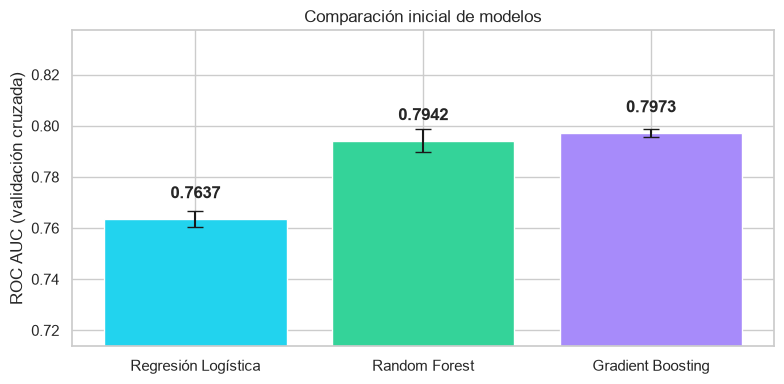

In [14]:
nombres = list(resultados_cv)
medias = [resultados_cv[n].mean() for n in nombres]
desvios = [resultados_cv[n].std() for n in nombres]

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(nombres, medias, yerr=desvios, capsize=6,
                color=["#22d3ee", "#34d399", "#a78bfa"])
ax.set_ylim(min(medias) - 0.05, max(medias) + 0.04)
ax.set_ylabel("ROC AUC (validación cruzada)")
ax.set_title("Comparación inicial de modelos")
for barra, media in zip(barras, medias):
    ax.text(barra.get_x() + barra.get_width() / 2, media + 0.008,
            f"{media:.4f}", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Ajuste de hiperparámetros

Con `GridSearchCV` se prueban varias combinaciones por modelo, siempre con validación cruzada sobre el conjunto de entrenamiento y ROC AUC como criterio. Se selecciona el modelo con mejor ROC AUC medio en validación.

In [15]:
grids = {
    "Regresión Logística": {
        "pipeline": build_pipeline(
            LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
        ),
        "params": {
            "classifier__C": [0.01, 0.1, 1.0, 10.0],
            "classifier__class_weight": [None, "balanced"],
        },
    },
    "Random Forest": {
        "pipeline": build_pipeline(
            RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)
        ),
        "params": {
            "classifier__max_depth": [None, 15],
            "classifier__min_samples_leaf": [1, 5],
            "classifier__class_weight": ["balanced"],
        },
    },
    "Gradient Boosting": {
        "pipeline": build_pipeline(
            HistGradientBoostingClassifier(random_state=RANDOM_STATE)
        ),
        "params": {
            "classifier__learning_rate": [0.05, 0.1],
            "classifier__max_iter": [200],
            "classifier__max_leaf_nodes": [31, 63],
            "classifier__class_weight": ["balanced"],
        },
    },
}

resultados = {}
mejor_nombre = None
mejor_score = -np.inf
mejor_modelo = None

for nombre, config in grids.items():
    print(f"Ajustando {nombre}...")
    busqueda = GridSearchCV(
        config["pipeline"],
        config["params"],
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
    )
    busqueda.fit(X_train, y_train)
    resultados[nombre] = {
        "mejores_params": {
            k.replace("classifier__", ""): v for k, v in busqueda.best_params_.items()
        },
        "cv_roc_auc": busqueda.best_score_,
    }
    print(f"  ROC AUC CV = {busqueda.best_score_:.4f}  |  {resultados[nombre]['mejores_params']}")
    if busqueda.best_score_ > mejor_score:
        mejor_nombre, mejor_score, mejor_modelo = nombre, busqueda.best_score_, busqueda.best_estimator_

print(f"\nMejor modelo: {mejor_nombre} (ROC AUC CV = {mejor_score:.4f})")

Ajustando Regresión Logística...


  ROC AUC CV = 0.7639  |  {'C': 0.1, 'class_weight': 'balanced'}
Ajustando Random Forest...


  ROC AUC CV = 0.7949  |  {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_leaf': 5}
Ajustando Gradient Boosting...


  ROC AUC CV = 0.7977  |  {'class_weight': 'balanced', 'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 31}

Mejor modelo: Gradient Boosting (ROC AUC CV = 0.7977)


In [16]:
tabla = pd.DataFrame({
    nombre: {
        "Mejores hiperparámetros": str(info["mejores_params"]),
        "ROC AUC (CV)": round(info["cv_roc_auc"], 4),
    }
    for nombre, info in resultados.items()
}).T
tabla

,Mejores hiperparámetros,ROC AUC (CV)
Regresión Logística,"{'C': 0.1, 'class_weight': 'balanced'}",0.7639
Random Forest,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.7949
Gradient Boosting,"{'class_weight': 'balanced', 'learning_rate': ...",0.7977


## 6. Evaluación sobre el conjunto de prueba

El 20% reservado no se usó ni para entrenar ni para ajustar. Se reportan las métricas habituales y las curvas ROC / precisión-recall.

In [17]:
y_pred = mejor_modelo.predict(X_test)
y_proba = mejor_modelo.predict_proba(X_test)[:, 1]

metricas = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred, zero_division=0),
    "f1": f1_score(y_test, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, y_proba),
    "pr_auc": average_precision_score(y_test, y_proba),
}
for clave, valor in metricas.items():
    print(f"{clave:10s}: {valor:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, target_names=["no", "yes"], digits=4))

accuracy  : 0.8252
precision : 0.3613
recall    : 0.6437
f1        : 0.4628
roc_auc   : 0.8052
pr_auc    : 0.4678

Reporte de clasificación:
              precision    recall  f1-score   support

          no     0.9473    0.8492    0.8956      7985
         yes     0.3613    0.6437    0.4628      1058

    accuracy                         0.8252      9043
   macro avg     0.6543    0.7464    0.6792      9043
weighted avg     0.8788    0.8252    0.8450      9043



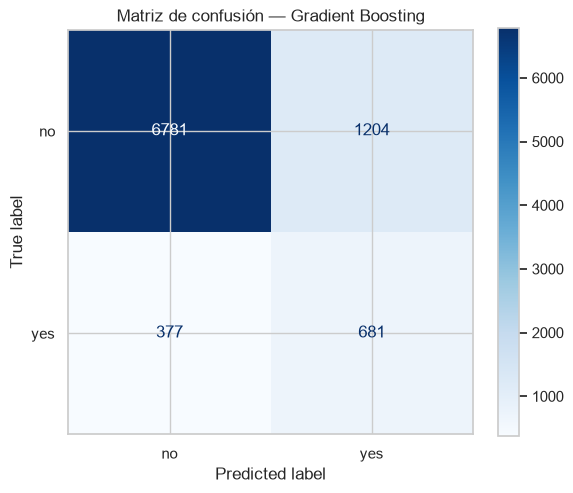

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["no", "yes"], cmap="Blues", ax=ax
)
ax.set_title(f"Matriz de confusión — {mejor_nombre}")
plt.tight_layout()
plt.show()

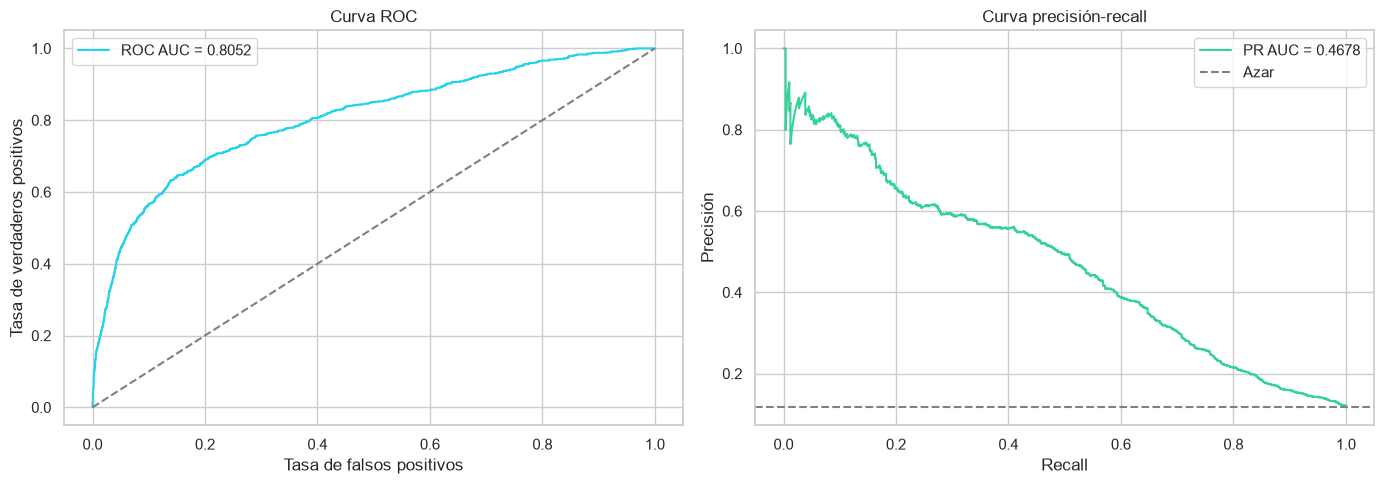

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[0].plot(fpr, tpr, color="#22d3ee", label=f"ROC AUC = {metricas['roc_auc']:.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].set_title("Curva ROC")
axes[0].legend()

precision, recall, _ = precision_recall_curve(y_test, y_proba)
axes[1].plot(recall, precision, color="#34d399",
             label=f"PR AUC = {metricas['pr_auc']:.4f}")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Azar")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisión")
axes[1].set_title("Curva precisión-recall")
axes[1].legend()

plt.tight_layout()
plt.show()

### 6.1 ¿Qué variables pesan más?

Se usa **importancia por permutación**: se desordena cada columna y se mide cuánto empeora el ROC AUC. Funciona con cualquier modelo y respeta las variables originales (no las columnas one-hot).

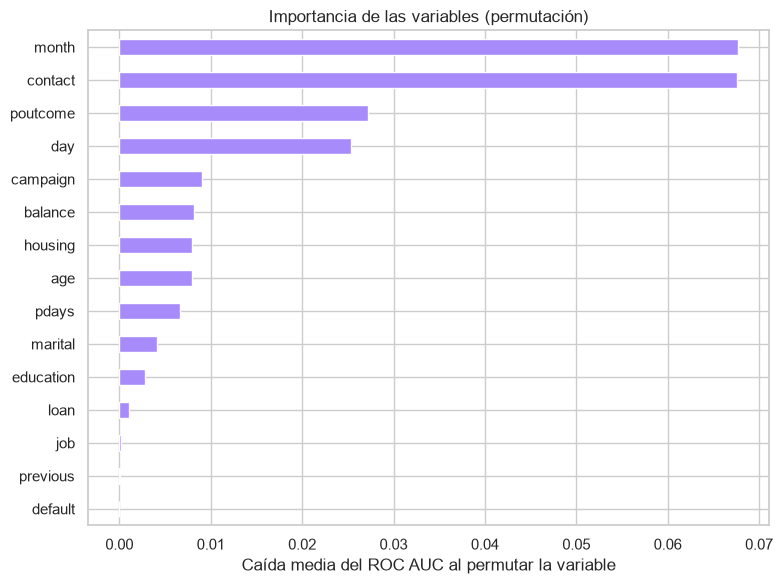

month        0.0677
contact      0.0676
poutcome     0.0272
day          0.0254
campaign     0.0090
balance      0.0082
housing      0.0080
age          0.0080
pdays        0.0067
marital      0.0042
education    0.0028
loan         0.0010
job          0.0001
previous     0.0001
default     -0.0000
dtype: float64

In [20]:
permutacion = permutation_importance(
    mejor_modelo, X_test, y_test, scoring="roc_auc",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
importancias = (
    pd.Series(permutacion.importances_mean, index=FEATURES)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 6))
importancias.plot(kind="barh", color="#a78bfa", ax=ax)
ax.set_xlabel("Caída media del ROC AUC al permutar la variable")
ax.set_title("Importancia de las variables (permutación)")
plt.tight_layout()
plt.show()

importancias.sort_values(ascending=False).round(4)

## 7. Conclusiones

- El desbalance hace que la exactitud no sea una buena métrica; el modelo se evalúa con **ROC AUC** y **PR AUC**.
- Se descartó `duration` por fuga de información, así que las métricas son **realistas para producción**.
- El preprocesamiento vive dentro del `Pipeline`, lo que evita contaminar el conjunto de prueba.
- El mejor modelo según validación cruzada se guarda con `joblib` y se sirve con `app.py`.

### Reproducir y desplegar

```bash
python train.py      # entrena y guarda model/bank_pipeline.joblib
python app.py        # servicio web en http://localhost:9696
docker build -t bank-marketing-capstone .
docker run --rm -p 9696:9696 bank-marketing-capstone
```

In [21]:
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

bundle = {
    "model": mejor_modelo,
    "model_name": mejor_nombre,
    "features": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "categories": {col: sorted(df[col].unique().tolist()) for col in CATEGORICAL_FEATURES},
    "target": TARGET,
    "threshold": 0.5,
    "test_metrics": {k: round(v, 4) for k, v in metricas.items()},
}
joblib.dump(bundle, MODEL_DIR / "bank_pipeline.joblib")
print("Modelo guardado en model/bank_pipeline.joblib")

Modelo guardado en model/bank_pipeline.joblib
